# Consumption overview

In [1]:
import pandas as pd
import json

import seaborn as sns

import numpy as np

In [2]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [3]:
results_part1 = pd.read_csv("../output/Venturelli2018/results_communities_12_1000s_part1.tsv",sep="\t")
results_part2 = pd.read_csv("../output/Venturelli2018/results_communities_12_1000s_part2.tsv",sep="\t")
results = pd.concat([results_part1,results_part2]).reset_index(drop=True)

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]

In [4]:
communities_12_exp_abundance = pd.read_csv("../data/Venturelli2018/generated/communities_12_exp_abundance.tsv",sep="\t",index_col=[0,1])
communities_12_exp_abundance

6
ER-  Blautia_hydrogenotrophica_DSM_10507     0.0109
     Collinsella_aerofaciens_ATCC_25986      0.0255
     Bacteroides_uniformis_ATCC_8492         0.3809
     Prevotella_copri_CB7_DSM_18205          0.0003
     Bacteroides_ovatus_ATCC_8483            0.1343
...                                             ...
NONE Eggerthella_lenta_DSM_2243              0.0168
     Faecalibacterium_prausnitzii_A2_165     0.2393
     Clostridium_hiranonis_TO_931_DSM_13275  0.0212
     Desulfovibrio_piger_ATCC_29098          0.0019
     Eubacterium_rectale_ATCC_33656          0.0086

[144 rows x 1 columns]

### Consumption - Frequencies 

**Average across all solutions: donor==environment**

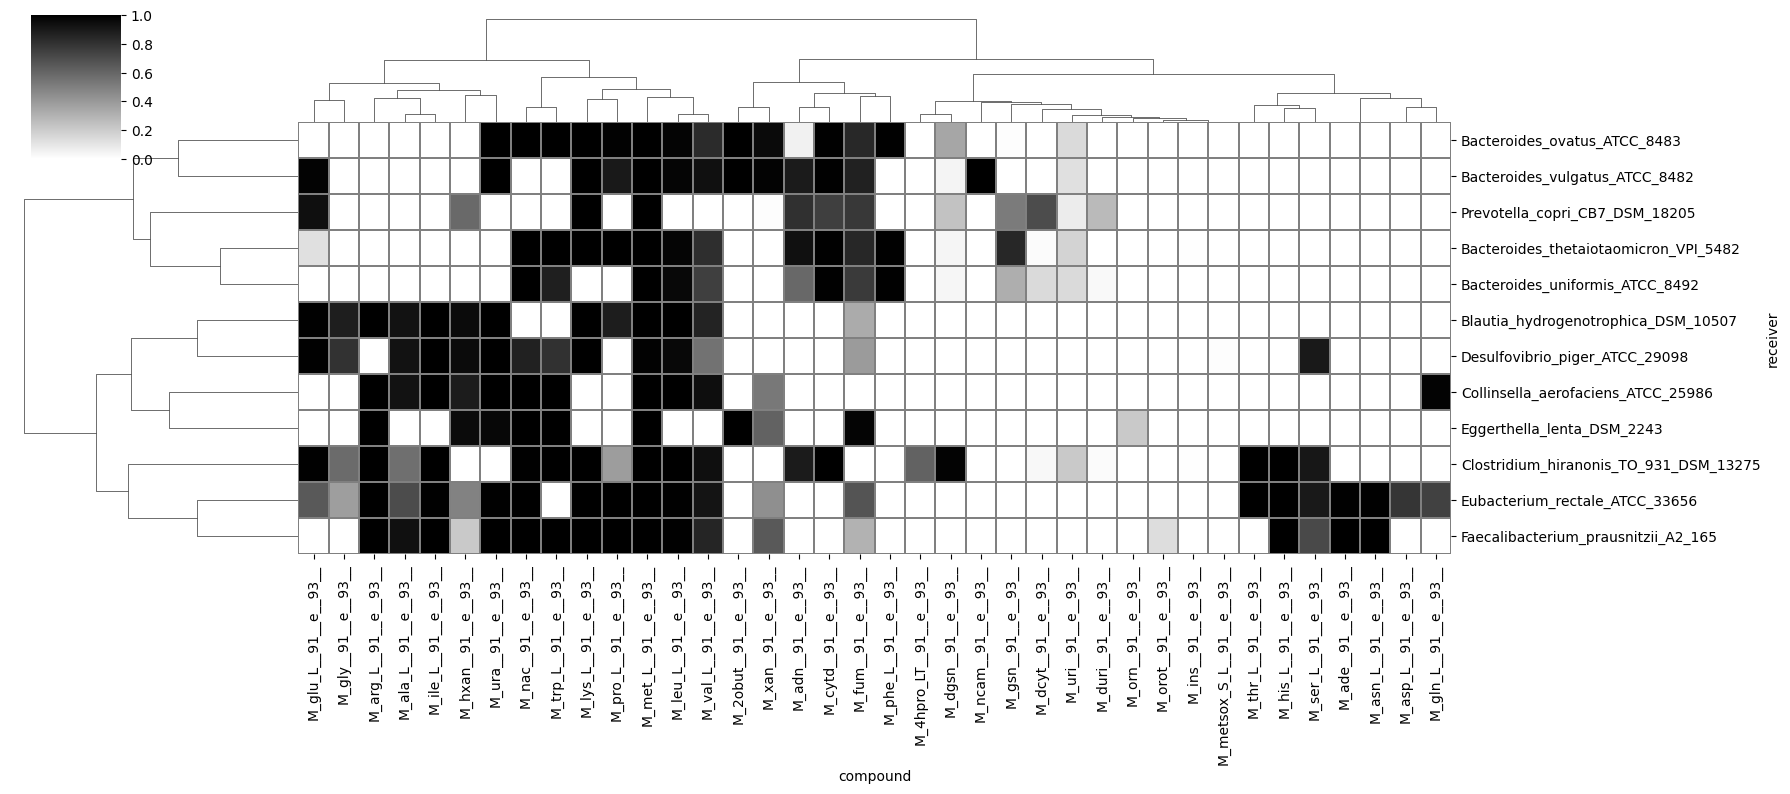

In [5]:
results_env = results[(results.donor=="environment")]
results_env = results_env[["receiver","compound","frequency"]]
# Find mean of frequencies
results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Average across all solutions: donor!=environment**

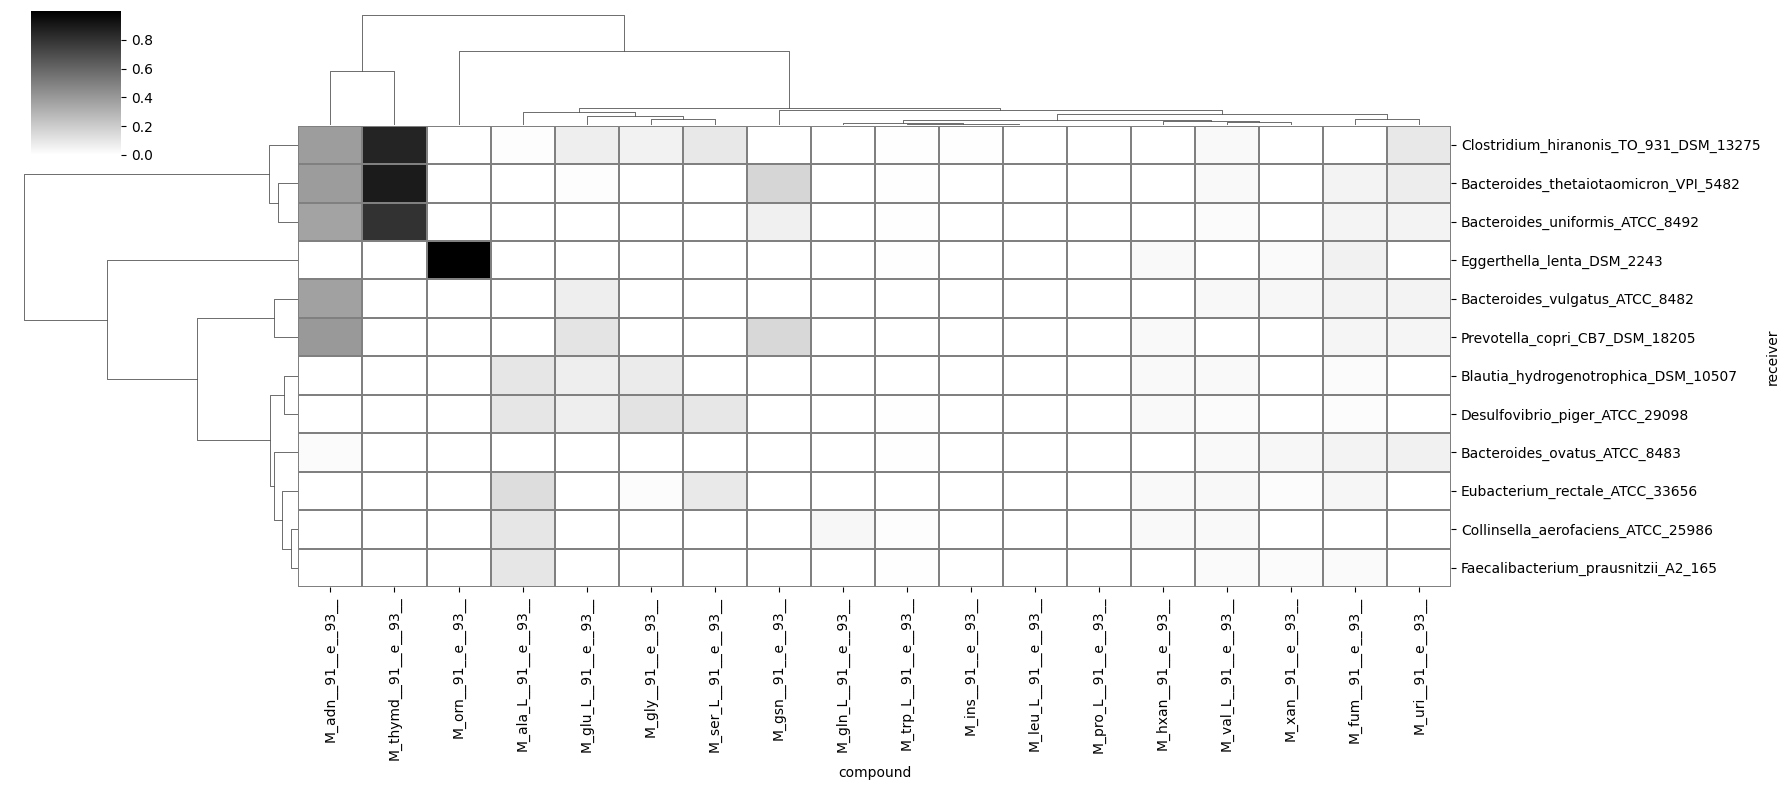

In [6]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment")]
results_env = results_env[["receiver","compound","frequency"]]

results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Average across all solutions: donor==environment|member**

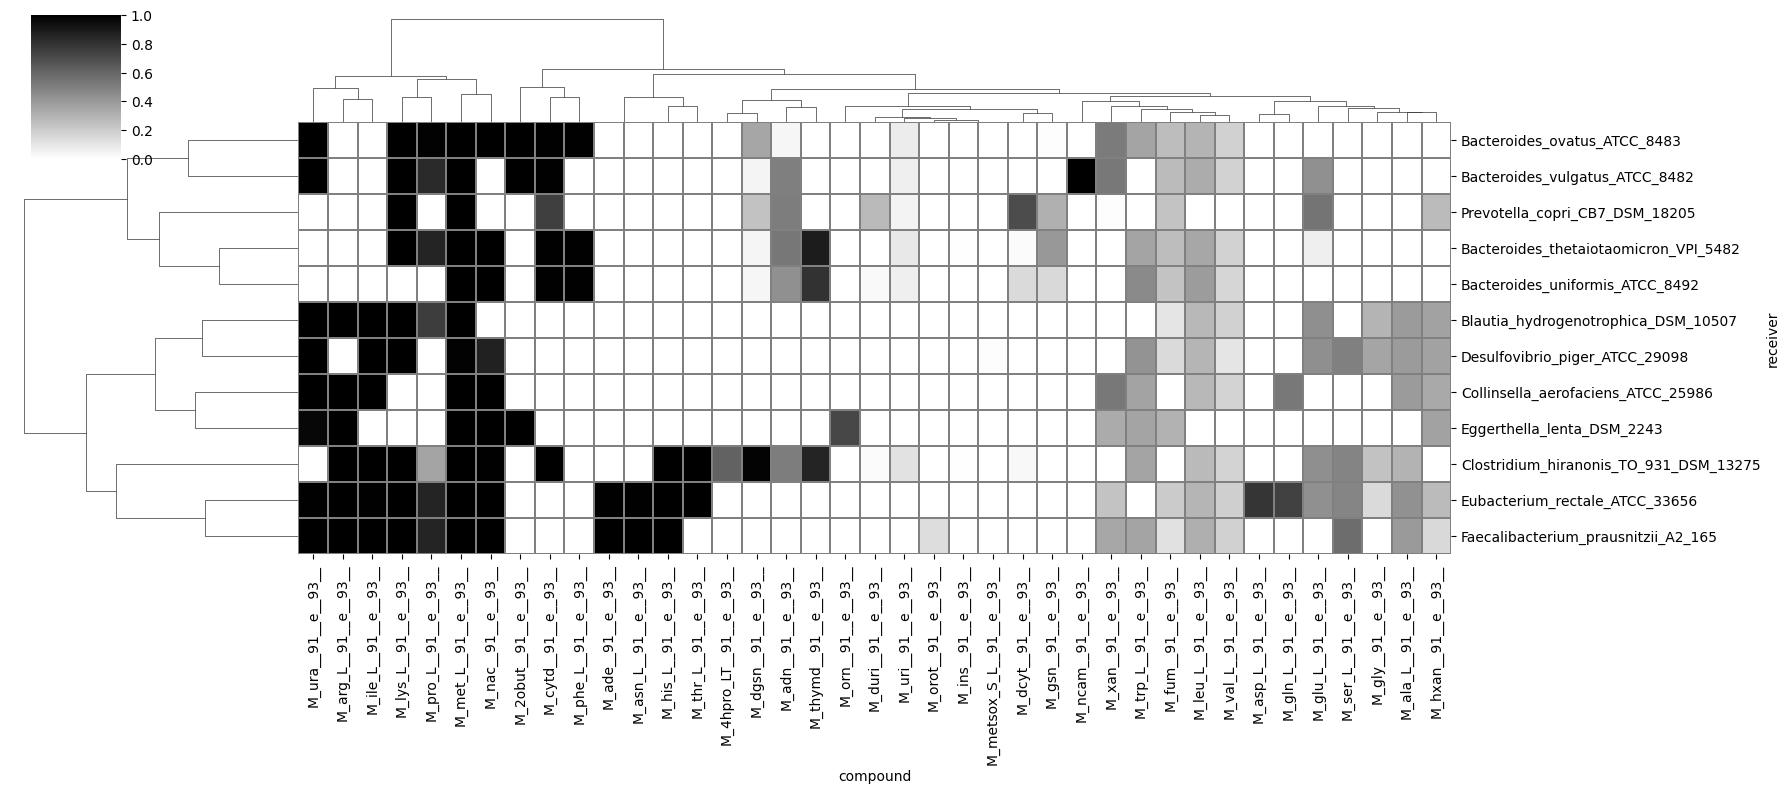

In [7]:
results_env = results[(results.receiver!="environment")]
results_env = results_env[["receiver","compound","frequency"]]

results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey",
              )

#### Sum (but average across communities)

Here we find the sum of the frequencies. This is because one member may have different sources of the same compound.

**Sum (with average across communities) - donor!=environment & receiver!=environment**

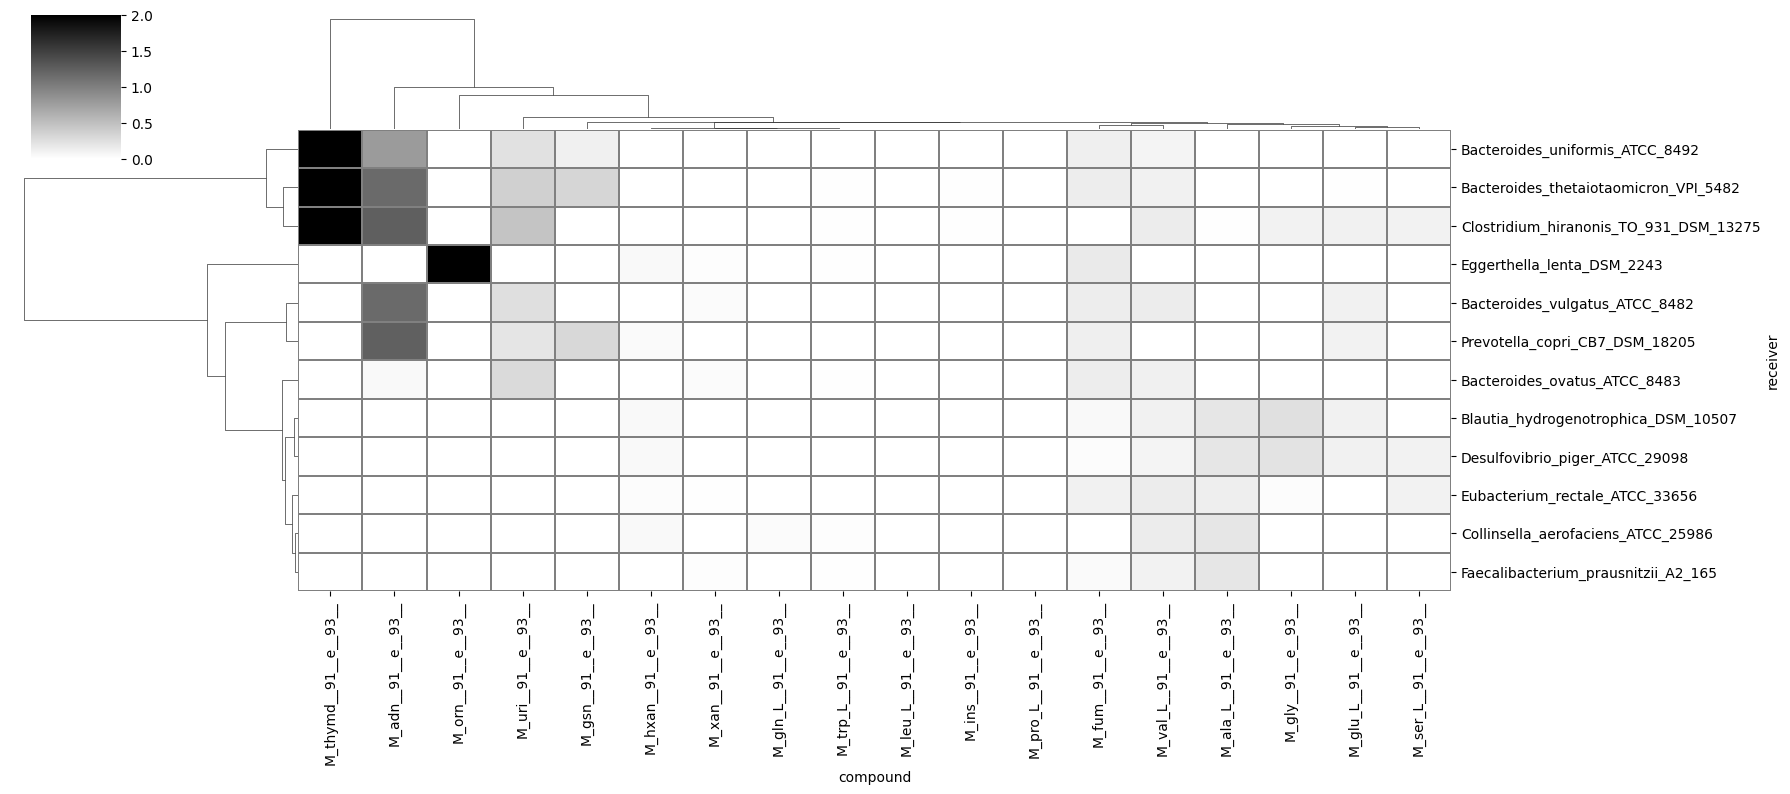

In [8]:
results_mean_freq = results[(results.receiver!="environment") & (results.donor!="environment")]
results_mean_freq = results_mean_freq[(results_mean_freq.compound.isin(metid2metname.keys()))]

# Get average frequency across all communities
results_mean_freq = results_mean_freq[["receiver","donor","compound","frequency"]].groupby(["receiver","donor","compound"]).mean()
results_mean_freq = results_mean_freq.reset_index()

# Sum up the contribution from each member
results_mean_freq = results_mean_freq[["receiver","compound","frequency"]].groupby(["receiver","compound"]).sum()

sns.clustermap(results_mean_freq["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               vmax=2,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Sum (with average across communities) - donor=environment|othermember**

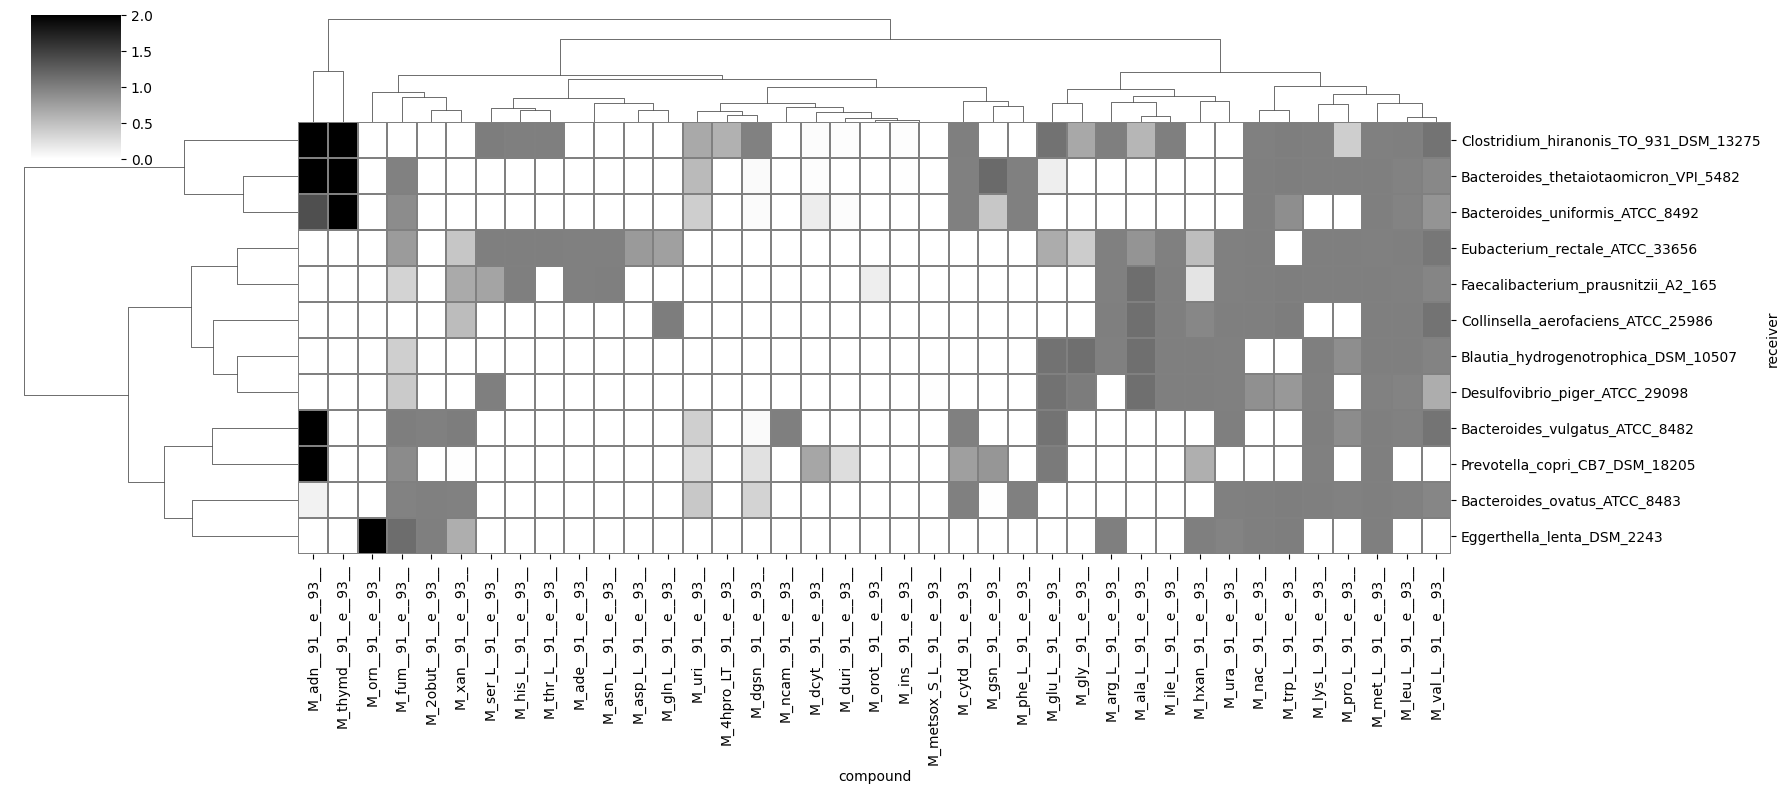

In [9]:
results_mean_freq = results[(results.receiver!="environment")]
results_mean_freq = results_mean_freq[(results_mean_freq.compound.isin(metid2metname.keys()))]

# Get average frequency across all communities
results_mean_freq = results_mean_freq[["receiver","donor","compound","frequency"]].groupby(["receiver","donor","compound"]).mean()
results_mean_freq = results_mean_freq.reset_index()



# Sum up the contribution from each member
results_mean_freq = results_mean_freq[["receiver","compound","frequency"]].groupby(["receiver","compound"]).sum()
sns.clustermap(results_mean_freq["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               vmax=2,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")